# Data Visualization Demo - Public Health Data Analysis

**Purpose:** Demonstrate visualization capabilities for policy-oriented health data analysis

**Core Functionalities:**
- Trend analysis over time
- Country comparisons
- Correlation analysis (modifiable factors)
- Regional comparisons
- Distribution analysis

**Technical Stack:**
- matplotlib for charts
- pandas for data handling
- SOLID design principles

In [1]:
# Import required modules
import sys
import os

# Add project root to path
sys.path.insert(0, os.path.abspath('..'))

# Import data modules
from task1.data_filter import get_data_as_dataframe
from task1.visualization import (
    plot_country_trend,
    plot_multi_country_comparison,
    plot_scatter_correlation,
    plot_regional_comparison,
    plot_distribution_histogram,
    plot_multi_metric_trends,
    ensure_output_directory
)

import pandas as pd
import matplotlib.pyplot as plt

# Configure matplotlib for better display
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Modules imported successfully!")

✅ Modules imported successfully!


## 1. Load Data

Load health data from database for visualization

In [2]:
# Load data from CSV (using cleaned data)
DB_PATH = "data/life_expectancy_cleaned.csv"

# Read CSV directly for demo
df = pd.read_csv(DB_PATH)

# Display data info
print(f"Dataset shape: {df.shape}")
print(f"Countries: {df['country'].nunique()}")
print(f"Year range: {df['year'].min()} - {df['year'].max()}")
print("\nFirst few rows:")
df.head()

Dataset shape: (3111, 32)
Countries: 183
Year range: 2000 - 2016

First few rows:


,country,country_code,region,year,life_expect,life_exp60,adult_mortality,infant_mort,age1-4mort,alcohol,...,che_gdp,une_pop,une_infant,une_life,une_hiv,une_gni,une_poverty,une_edu_spend,une_literacy,une_school
0,Angola,AGO,Africa,2000,47.33730,14.73400,383.5583,0.137985,0.025695,1.47439,...,1.90860,16395.473,122.2,46.522,1.0,2530.0,32.3,2.60753,NaN,NaN
1,Angola,AGO,Africa,2001,48.19789,14.95963,372.3876,0.133675,0.024500,1.94025,...,4.48352,16945.753,118.9,47.059,1.1,2630.0,NaN,NaN,67.40542,NaN
2,Angola,AGO,Africa,2002,49.42569,15.20010,354.5147,0.128320,0.023260,2.07512,...,3.32946,17519.417,115.1,47.702,1.2,3180.0,NaN,NaN,NaN,NaN
3,Angola,AGO,Africa,2003,50.50266,15.39144,343.2169,0.122040,0.021925,2.20275,...,3.54797,18121.479,110.8,48.440,1.3,3260.0,NaN,NaN,NaN,NaN
4,Angola,AGO,Africa,2004,51.52863,15.56860,333.8711,0.115700,0.020545,2.41274,...,3.96720,18758.145,106.2,49.263,1.3,3560.0,NaN,NaN,NaN,NaN


## 2. Trend Analysis - Life Expectancy Over Time

Visualize how life expectancy has changed for specific countries

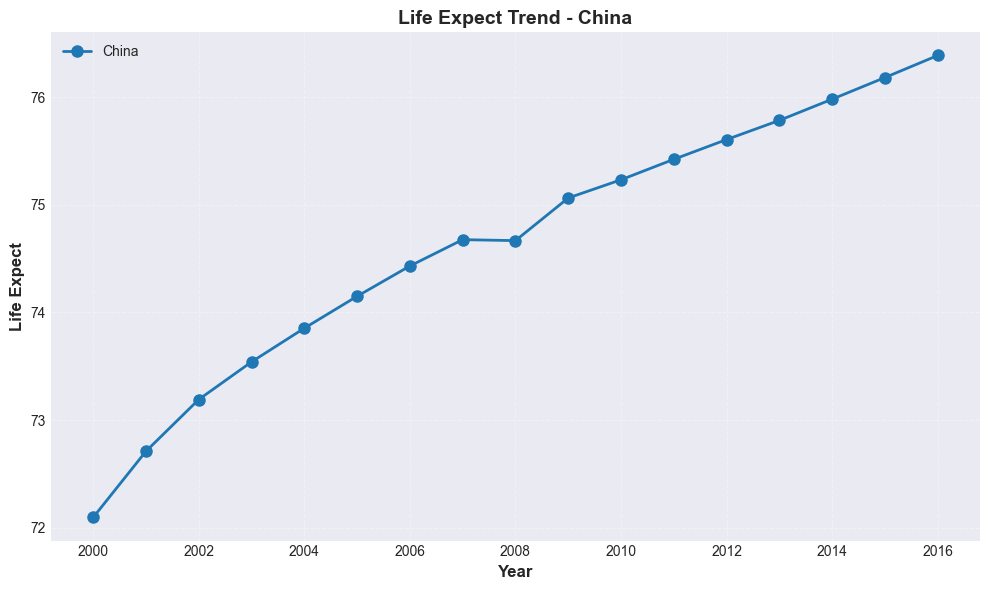

In [3]:
# Plot trend for China
plot_country_trend(df, "China", "life_expect")

# This will display the trend of life expectancy in China over the years

## 3. Country Comparison - Healthcare Spending

Compare healthcare spending (gghe-d) across multiple countries

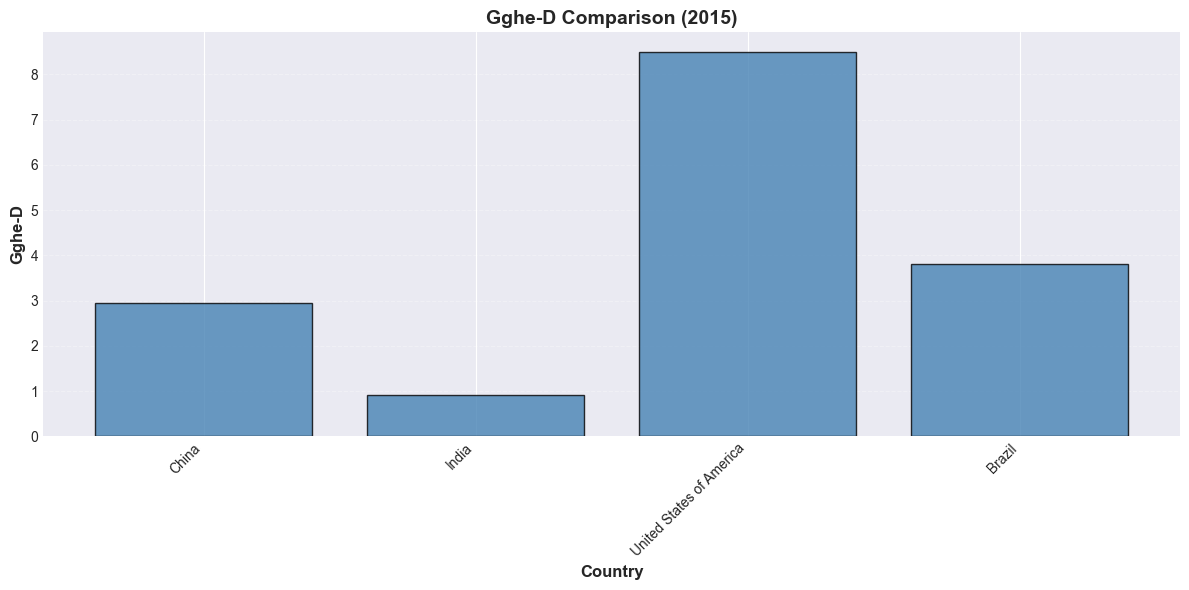

In [4]:
# Compare healthcare spending across select countries
countries = ["China", "India", "United States of America", "Brazil"]
plot_multi_country_comparison(df, countries, "gghe-d", year=2015)

## 4. Correlation Analysis - Water Access vs Life Expectancy

**Policy Relevance:** Basic water access (r=0.831) is a highly modifiable factor

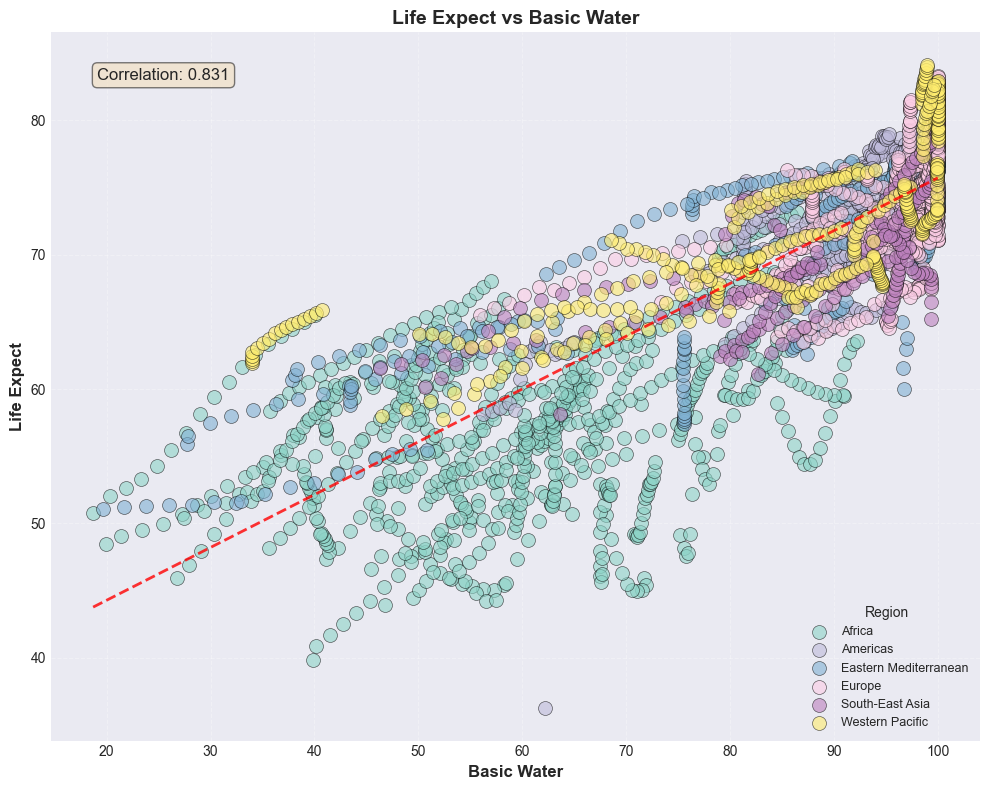

In [5]:
# Scatter plot showing correlation between water access and life expectancy
plot_scatter_correlation(df, "basic_water", "life_expect", color_by="region")

## 5. Regional Comparison - Life Expectancy by Region

Compare average life expectancy across different world regions

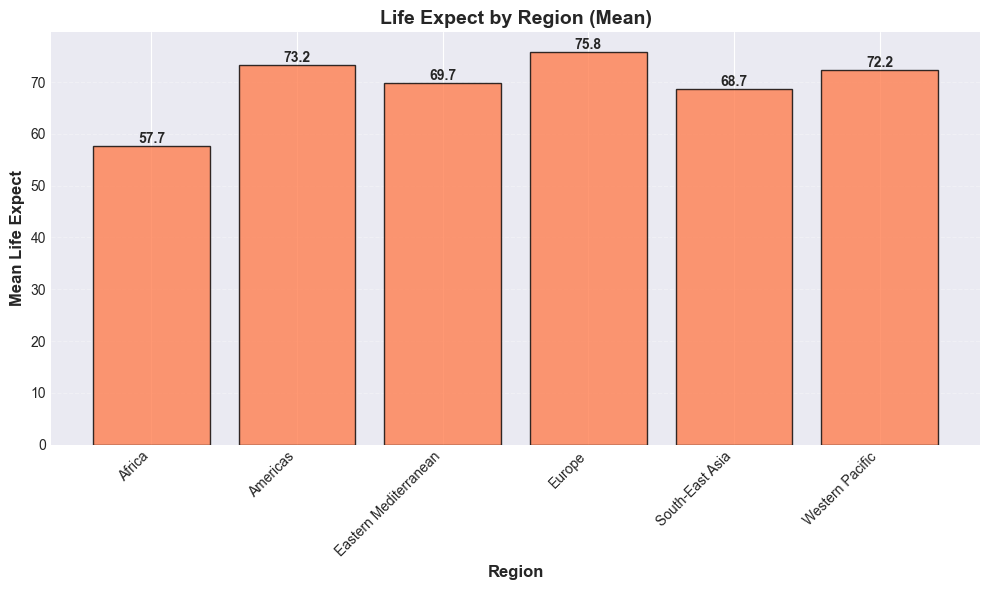

In [6]:
# Regional comparison of life expectancy
plot_regional_comparison(df, "life_expect", aggregation="mean")

## 6. Distribution Analysis - BMI Distribution

Analyze the distribution of BMI (Body Mass Index) across all records

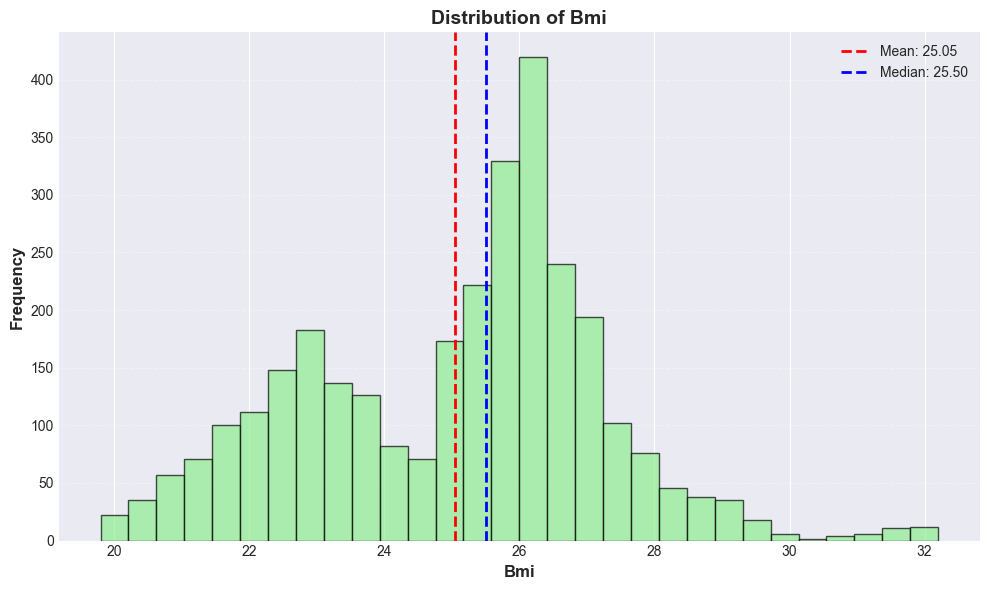

In [7]:
# Distribution histogram for BMI
plot_distribution_histogram(df, "bmi", bins=30)

## 7. Multi-Metric Trends - Comprehensive View

View multiple modifiable factors for a single country

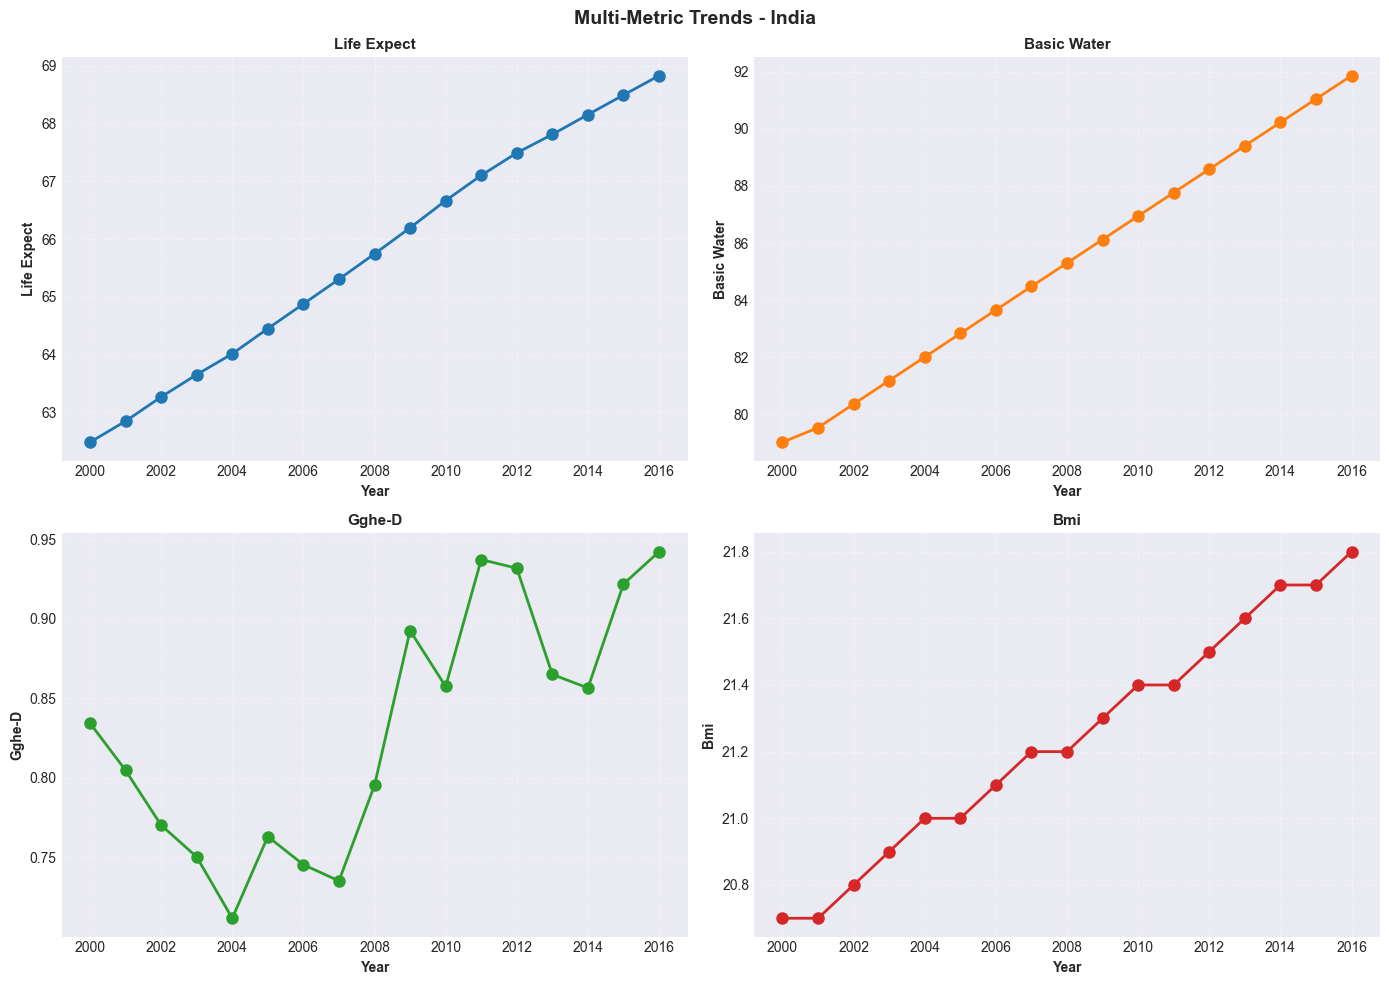

In [8]:
# Multi-metric trends for India (showing modifiable factors)
metrics = ["life_expect", "basic_water", "gghe-d", "bmi"]
plot_multi_metric_trends(df, "India", metrics, figsize=(14, 10))

## 8. Export Visualizations

Save high-quality figures for reports

In [10]:
# Create output directory
output_dir = ensure_output_directory("output/figures")
print(f"Output directory created: {output_dir}")

# Save all 6 visualizations with high quality (300 DPI)
print("\nSaving visualizations...")

# 1. Country trend (China life expectancy)
plot_country_trend(df, "China", "life_expect", 
                   save_path="output/figures/china_life_expect_trend.png")

# 2. Multi-country comparison (Healthcare spending)
plot_multi_country_comparison(df, countries, "gghe-d", year=2015,
                               save_path="output/figures/healthcare_spending_comparison.png")

# 3. Correlation scatter plot (Water access vs Life expectancy)
plot_scatter_correlation(df, "basic_water", "life_expect", 
                         color_by="region",
                         save_path="output/figures/water_life_correlation.png")

# 4. Regional comparison (Life expectancy by region)
plot_regional_comparison(df, "life_expect", aggregation="mean",
                         save_path="output/figures/regional_life_expectancy.png")

# 5. Distribution histogram (BMI distribution)
plot_distribution_histogram(df, "bmi", bins=30,
                            save_path="output/figures/bmi_distribution.png")

# 6. Multi-metric trends (India comprehensive view)
plot_multi_metric_trends(df, "India", metrics, figsize=(14, 10),
                         save_path="output/figures/india_multi_metrics.png")

print("\n✅ All 6 visualizations saved successfully!")

Output directory created: output/figures

Saving visualizations...
Plot saved to: output/figures/china_life_expect_trend.png
Plot saved to: output/figures/healthcare_spending_comparison.png
Plot saved to: output/figures/water_life_correlation.png
Plot saved to: output/figures/regional_life_expectancy.png
Plot saved to: output/figures/bmi_distribution.png
Plot saved to: output/figures/india_multi_metrics.png

✅ All 6 visualizations saved successfully!


## Summary

This notebook demonstrated 6 types of visualizations for health data analysis:

1. **Trend Analysis** - Time series line charts
2. **Country Comparisons** - Bar charts for multi-country comparison
3. **Correlation Analysis** - Scatter plots with trend lines (r=0.831 for water access)
4. **Regional Comparisons** - Grouped bar charts by region
5. **Distribution Analysis** - Histograms showing data distribution
6. **Multi-Metric Analysis** - Subplot grids for comprehensive view

**Key Features:**
- All functions follow SOLID principles (SRP - each function has one purpose)
- High-quality output (300 DPI)
- Flexible color schemes and styling
- Support for saving to files
- Policy-oriented focus on modifiable factors